# Numbers needed for text

In [1]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import string
import zarr
import warnings
from tqdm.notebook import tqdm

import matplotlib as mpl
from matplotlib import pyplot as plt

from funcs_support import get_filepaths,get_params,utility_save,utility_print,load_shp,nan_argmax_xr
from funcs_readregs import coeffs_mortality, coeffs_gdppc, coeffs_payroll

dir_list = get_params()



In [2]:
params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','popwght':True},
               'payroll':{'varname':'days90plus','geo_typ':'adm2-us','popwght':True}}

nsamples = 1000
rng = np.random.default_rng()

In [3]:
def get_coeff_draws(proc,load_kwargs = {},
                    rng = rng,
                    nsamples = nsamples):
    ''' Get MC draws of coefficients

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    coeffs_mvn : xr.DataArray
    '''

    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)
    return coeffs_mvn

In [4]:
def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

### Calendar years for each GWL
At first mention, GWL 2 ("reached on average in year XXXX across the BCD-ME")

### The inflection point ("ideal temperature") for Burke et al. GDP per capita growth

In [5]:
dmgf = load_dmgfs('gdppc')

In [6]:
infl_points = dmgf.Tref.isel(Tref = dmgf.mean('sidx').argmax('Tref'))

for pb in infl_points.proj_base.values:
    print(f'{pb}: {str(infl_points.sel(proj_base=pb).values)} degC')

ERA5: 13 degC
GMFD: 17 degC
JRA-3Q: 12 degC
MERRA2: 15 degC
UDel: 14 degC


### Proporton of regression uncertainty by area, population

In [5]:
gwl = 2
for proc in params_proc:

    # Load shapefile# Load shapefile
    gdf = load_shp(proc)
    
    # Load partitioned uncertainty 
    fn_uncerts = f'{dir_list['proc']}uncert_parts/uncert_parts_{proc}_wregunc.zarr'
    uncerts_all = xr.open_zarr(fn_uncerts).isel(sample=0)
    uncerts_all = uncerts_all.set_index({'poly_idx':'locid'})
    plot_data = uncerts_all.sel(gwl=gwl,typ='norm',poly_idx=gdf.locid.values).load()
    
    # Get which uncertainty source is most important 
    srcs = plot_data.to_dataarray()
    src_idxs = nan_argmax_xr(srcs,dim='variable').dropna('poly_idx').astype(int)
    srcs = srcs.sel(poly_idx = src_idxs.poly_idx).isel(variable=src_idxs)['variable']
    srcs = srcs.to_dataframe()['variable'].iloc[:,[0]]
    
    srcs = srcs.reset_index().rename({'poly_idx':'locid'},axis=1)

    # Merge into gdf
    gdf = gdf.set_index('locid').join(srcs.set_index('locid'))
    gdf = gdf.iloc[(~gdf['variable'].isnull()).values,:]
    gdf = gdf.join(plot_data['uncreg'].rename({'poly_idx':'locid'}).to_dataframe()['uncreg'])

    # Reproj into WGS84 for area calcs
    gdf = gdf.to_crs('EPSG:4087')

    print('\n---- '+proc+':')

    # Get relative area of globe for each
    gdf_areas = gdf.dissolve(by='variable').area
    print('\n-- by area')
    print(str(np.round((gdf.uncreg*gdf.area).sum()/gdf.area.sum(),2)))
    print(str(gdf_areas / gdf_areas.sum()))

    # Now, get by population
    if proc == 'mortality':
        preds = xr.open_zarr('/glade/derecho/scratch/schwarzwald/impact_uncertainty/aux/all_preds.zarr')
        pop = preds[['pop']].sel(gwl=0.61,ageset='agetotal',pred_ssp='ssp3',pred_model='high')
        pop = pop.mean('year').load()

        gdf = gdf.join(pop.rename({'hierid':'locid'}).to_dataframe()['pop'])

        gdf_pops = gdf.groupby('variable')['pop'].sum()
    elif proc == 'gdppc':
        gdf_pops = gdf.groupby('variable')['POP_CNTRY'].sum() 
        gdf = gdf.rename({'POP_CNTRY':'pop'},axis=1)
    elif proc == 'payroll':
        # Load population by grid cell
        pop_fn = dir_list['aux']+'pop_fx_LANDSCAN_conus_day_025deg_2016.nc'
        pop = xr.open_dataset(pop_fn)
    
        with xa.set_options(silent=True):
            wm = xa.pixel_overlaps(pop,gdf.to_crs('EPSG:4326'))
            with xa.set_options(impl='numba'):
                agg = xa.aggregate(pop,wm)
                agg_out = agg.to_dataset()
        
        agg_out['locid'] = agg_out['STATE_FIPS']+agg_out['CNTY_FIPS']
        gdf = gdf.join(agg_out.to_dataframe().set_index('locid')['pop'])
        gdf['pop'] = (gdf.to_crs('EPSG:4087').geometry.area*gdf['pop'])
        gdf_pops = gdf.groupby('variable')['pop'].sum()
    print('\n-- by pop')
    print(str(np.round((gdf['uncreg']*gdf['pop']).sum()/gdf['pop'].sum(),2)))
    print(str(gdf_pops / gdf_pops.sum()))


---- mortality:

-- by area
0.43
variable
uncmod    0.009353
uncobs    0.696229
uncreg    0.294419
dtype: float64

-- by pop
0.42
variable
uncmod    0.095695
uncobs    0.410502
uncreg    0.493803
Name: pop, dtype: float64

---- gdppc:

-- by area
0.47
variable
uncint    0.000008
uncmod    0.046746
uncobs    0.416260
uncreg    0.536986
dtype: float64

-- by pop
0.39
variable
uncint   -0.000018
uncmod    0.021258
uncobs    0.558348
uncreg    0.420411
Name: POP_CNTRY, dtype: float64

---- payroll:

-- by area
0.33
variable
uncint    0.026518
uncmod    0.000645
uncobs    0.686352
uncreg    0.286486
dtype: float64

-- by pop
0.35
variable
uncint    0.013089
uncmod    0.000145
uncobs    0.588098
uncreg    0.398667
Name: pop, dtype: float64


## Change in extreme quantiles when using more than one reanalysis product

In [7]:
from distributed import Client
client = Client()
display(client)

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/distributed/node.py:188: UserWarning: Port 8787 is already in use.
Perhaps you already have a cluster running?
Hosting the HTTP server on port 40889 instead
  warnings.warn(


Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/40889/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/40889/status,Workers: 6
Total threads: 18,Total memory: 144.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:33033,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/40889/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:43711,Total threads: 3
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/37937/status,Memory: 24.00 GiB
Nanny: tcp://127.0.0.1:33979,


In [20]:
# Load impacts projections
proc = 'mortality'
fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
def load_impact(fn):
    ds_tmp = xr.open_zarr(fn,consolidated=False)
    ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
    ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})

    ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
    if 'idv' in ds_tmp.coords:
        ds_tmp = ds_tmp.reset_index('idv')
    ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
    return ds_tmp

with warnings.catch_warnings():
    # Silence zarr warnings related to the /.done flags used
    warnings.filterwarnings('ignore')
    dss = xr.concat([load_impact(fn) for fn in fns],
                dim='idv',join='outer')
dss = dss.sel(indflag='noInd',obstreat='sep',spec='pooled',timeframe='1980-2010',resolution='025deg')
dss = dss.sel(gwl=[0.61,2])
dss = dss.reset_index('idv').set_index(idv = ['model','exprun']).drop_vars(['experiment','run'])

In [68]:
dss['poly_idx'] = dss['locid']

In [69]:
import copy
# Figure out how many BCD-ME members reach a given GWL
# (copy.deepcopy() necessary as a workaround around a numpy bug
# affecting the unstack a few lines down that's triggered 
# indirectly by the reset_index here)
gwl_counter = copy.deepcopy(dss.maxgwl).load().reset_index('idv').groupby(['model','maxgwl']).count()
gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
#print(gwl_counter)

In [70]:
#---------------------------
# Uncertainty partitioning over a balanced panel up to GWL 3
#---------------------------
max_gwl = 3
if proc == 'payroll':
    nruns = 10
else:
    nruns = 13

gwlmods = gwl_counter.sel(maxgwl=3)
proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values

dss_tmp = dss.isel(idv = dss.maxgwl.load()>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
dss_tmp = dss_tmp.unstack('idv')['d'+proc]
dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()

In [71]:
ddss_tmp = dss_tmp.sel(gwl=2) - dss_tmp.sel(gwl=0.61)
ddss_tmp2 = ddss_tmp.stack(idv = ['model','exprun']).dropna('idv',how='all').load()

In [98]:
dists = ((ddss_tmp2*pop).sum('poly_idx')/pop.sum('poly_idx'))

In [101]:
from scipy import stats as sstats

In [113]:
mortrates = np.arange(0,40,0.25)
kde = {'all':sstats.gaussian_kde(dists.values.flatten()),
       'GMFD':sstats.gaussian_kde(dists.sel(proj_base='GMFD').values.flatten())}
kdet = {typ:k(mortrates) for typ,k in kde.items()}

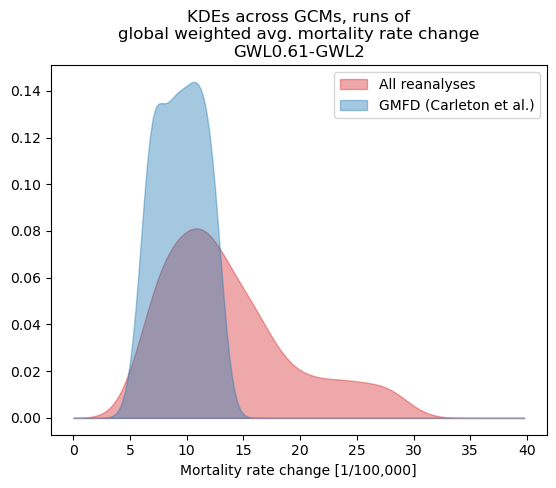

In [121]:
ax = plt.subplot()
ax.fill_between(mortrates,kdet['all'],color='tab:red',alpha=0.4,label='All reanalyses')
ax.fill_between(mortrates,kdet['GMFD'],color='tab:blue',alpha=0.4,label='GMFD (Carleton et al.)')
ax.set_title('KDEs across GCMs, runs of\nglobal weighted avg. mortality rate change\nGWL0.61-GWL2')
ax.set_xlabel('Mortality rate change [1/100,000]')
ax.legend()

In [73]:
qs = xr.concat([ddss_tmp.quantile(0.95,['proj_base','model','exprun']),
           ddss_tmp.sel(proj_base='GMFD').quantile(0.95,['model','exprun'])],
          dim=pd.Index(['all','GMFDonly'],name='typ'))

In [74]:
qs = qs.compute()

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


In [75]:
gdf = load_shp('mortality')

In [76]:
gdf

,gadmid,locid,color,ISO,AREA,PERIMETER,geometry
0,28115,CAN.1.2.28,1,CAN,0.001442,0.184641,"POLYGON ((-110.05459 53.3073, -110.00587 53.30..."
1,28116,CAN.1.17.403,2,CAN,0.000081,0.041724,"POLYGON ((-111.23055 52.91943, -111.22076 52.9..."
2,28119,CAN.2.34.951,3,CAN,0.000490,0.091736,"POLYGON ((-127.68527 55.2957, -127.69742 55.32..."
3,28120,CAN.11.259.4274,4,CAN,0.001212,0.183588,"POLYGON ((-77.7308 55.31879, -77.7103 55.3176,..."
4,28124,CAN.11.269.4448,5,CAN,0.489323,6.556768,"POLYGON ((-66.2594 54.99975, -65.24999 55, -64..."
...,...,...,...,...,...,...,...
24373,6905,BWA.1,24374,BWA,12.798809,18.094620,"POLYGON ((26.01723 -23.55865, 25.86139 -23.355..."
24374,6902,BWA.7,24375,BWA,11.378698,16.661345,"POLYGON ((22.50413 -18.11382, 22.98841 -18.018..."
24375,6915,BWA.6.16,24376,BWA,0.459842,3.292925,"POLYGON ((27.28497 -20.49781, 27.35821 -20.473..."
24376,6909,BWA.5,24377,BWA,3.274455,8.503536,"POLYGON ((23.05667 -23.31139, 23.55222 -23.313..."


In [77]:
qs.mean('poly_idx')

<xarray.DataArray 'dmortality' (typ: 2)> Size: 16B
array([21.98076007, 12.38993709])
Coordinates:
  * typ       (typ) StringDType(na_object=nan) 32B 'all' 'GMFDonly'
    quantile  float64 8B 0.95

In [78]:
pop = allpreds.pop.sel(ageset='agetotal',pred_ssp='ssp3',pred_model='high',gwl=2).mean('year').compute()
pop = pop.rename({'hierid':'poly_idx'})

In [79]:
qs

<xarray.DataArray 'dmortality' (typ: 2, poly_idx: 24378)> Size: 390kB
array([[14.70756282, 10.99688611, -2.82597083, ..., 25.76506818,
        28.1743256 , 32.26628721],
       [18.81929616, 13.5725523 , -1.45029467, ..., 11.86230244,
        15.68988334, 14.78825233]], shape=(2, 24378))
Coordinates:
  * typ       (typ) StringDType(na_object=nan) 32B 'all' 'GMFDonly'
  * poly_idx  (poly_idx) StringDType() 390kB 'CAN.1.2.28' ... 'BWA.4.13'
    locid     (poly_idx) StringDType() 390kB 'CAN.1.2.28' ... 'BWA.4.13'
    quantile  float64 8B 0.95

In [80]:
(qs*pop).sum('poly_idx')/pop.sum('poly_idx')

<xarray.DataArray (typ: 2)> Size: 16B
array([29.0621777 , 15.05410002])
Coordinates:
  * typ         (typ) StringDType(na_object=nan) 32B 'all' 'GMFDonly'
    quantile    float64 8B 0.95
    ageset      <U9 36B 'agetotal'
    degree      int64 8B 1
    gwl         float64 8B 2.0
    pred_model  <U4 16B 'high'
    pred_ssp    <U4 16B 'ssp3'

In [59]:
pop

<xarray.DataArray 'pop' (poly_idx: 24378)> Size: 195kB
array([136127.25572155,  38350.20884133, 836948.6780346 , ...,
       160240.59013195, 138505.0799903 , 731645.74894785], shape=(24378,))
Coordinates:
  * poly_idx    (poly_idx) <U35 3MB 'ABW' ... 'ZWE.9.R19a261b63a503c9c'
    ageset      <U9 36B 'agetotal'
    degree      int64 8B 1
    gwl         float64 8B 2.0
    pred_model  <U4 16B 'high'
    pred_ssp    <U4 16B 'ssp3'

## Table of models used

In [5]:
def ssp_parser(name):
    ''' Convert from lowercase filename SSPs to "official" SSP names '''
    m = re.match(r'ssp(\d)(\d)(\d)(-over)?', name.lower())
    if not m:
        raise ValueError(f'Unrecognized SSP format: {name}')

    major, tens, ones, over = m.groups()
    forcing = f'{tens}.{ones}'
    suffix = '-OS' if over else ''

    return f'SSP{major}-{forcing}{suffix}'

In [10]:
fns = glob.glob(dir_list['bcd_me']+'*_qdm_*.zarr')
fns = np.sort(fns)

has_data_array = xr.concat([xr.open_zarr(fn).has_data for fn in fns],
          dim='idv',join='outer').load()
has_data_array = has_data_array.where(~np.isnan(has_data_array),0)

/glade/derecho/scratch/schwarzwald/tmp/ipykernel_128539/2347832078.py:4: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  has_data_array = xr.concat([xr.open_zarr(fn).has_data for fn in fns],
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3535: ZarrUserWarning: Object at .done_v021 is not recognized as a component of a Zarr hierarchy.
  warnings.warn(
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/zarr/core/group.py:3535: ZarrUserWa

In [12]:
total_nruns = has_data_array.any('gwl').sum('idv')
print(f'Number of total runs (`tas`): {str(total_nruns.sel(variable='tas').values)}')
print(f'Number of total runs (`tasmax`): {str(total_nruns.sel(variable='tasmax').values)}')
print(f'Number of models: {str(len(fns))}')

Number of total runs (`tas`): 362
Number of total runs (`tasmax`): 199
Number of models: 22


In [21]:
df_bygwl = has_data_array.sel(gwl=slice(1,None)).set_index(idv = ['model','run','experiment']).unstack().sum(('run','experiment')).rename({'gwl':'GWL reached:'}).to_dataframe().reset_index().pivot(columns = 'GWL reached:',
                                                                                                                      index = ['variable','model'])
df_bygwl.columns = df_bygwl.columns.droplevel()

# Get total number of runs by GWL
totals = df_bygwl.groupby(['variable']).sum().astype(int)
totals['model'] = 'Total'
totals = totals.reset_index().set_index(['variable','model'])
# Concat back in
df_bygwl = pd.concat([df_bygwl,totals]).sort_index()
# Drop models without data
df_bygwl = df_bygwl.where(~(df_bygwl==0).all(axis=1)).dropna()

# Capitalize
df_bygwl.index = df_bygwl.index.rename({'model':'Model','variable':'Variable'})


# Change to integer dtype
df_bygwl = df_bygwl.astype(int)

# Print latex table
print(df_bygwl.to_latex())



\begin{tabular}{llrrrrrrr}
\toprule
 & GWL reached: & 1.000000 & 1.500000 & 2.000000 & 2.500000 & 3.000000 & 3.500000 & 4.000000 \\
Variable & Model &  &  &  &  &  &  &  \\
\midrule
\multirow[t]{23}{*}{tas} & ACCESS-CM2 & 1 & 1 & 1 & 1 & 1 & 1 & 0 \\
 & ACCESS-ESM1-5 & 24 & 24 & 24 & 24 & 5 & 5 & 5 \\
 & BCC-CSM2-MR & 2 & 2 & 2 & 2 & 2 & 1 & 0 \\
 & BCC-ESM1 & 1 & 1 & 0 & 0 & 0 & 0 & 0 \\
 & CAMS-CSM1-0 & 1 & 1 & 1 & 1 & 0 & 0 & 0 \\
 & CESM2-WACCM & 8 & 8 & 8 & 7 & 7 & 4 & 3 \\
 & CMCC-CM2-SR5 & 1 & 1 & 1 & 1 & 1 & 1 & 1 \\
 & CMCC-ESM2 & 1 & 1 & 1 & 1 & 1 & 1 & 1 \\
 & CNRM-CM6-1 & 18 & 18 & 18 & 18 & 15 & 12 & 6 \\
 & CNRM-ESM2-1 & 41 & 41 & 31 & 26 & 13 & 7 & 5 \\
 & CanESM5 & 86 & 86 & 86 & 86 & 86 & 86 & 79 \\
 & EC-Earth3 & 35 & 35 & 35 & 35 & 32 & 15 & 10 \\
 & EC-Earth3-Veg & 13 & 13 & 13 & 13 & 13 & 9 & 6 \\
 & FGOALS-g3 & 10 & 10 & 10 & 7 & 3 & 0 & 0 \\
 & IITM-ESM & 1 & 1 & 1 & 1 & 1 & 0 & 0 \\
 & IPSL-CM6A-LR & 14 & 14 & 14 & 14 & 14 & 11 & 10 \\
 & MIROC-ES2L & 1 & 1 & 1 

In [67]:
df_long = has_data_array.any('gwl').groupby(['model','experiment']).sum().sum('variable').stack(allv = ['model','experiment'])
df_long = df_long.where(df_long>0,drop=True)
df_long = df_long.to_dataframe()
#df_long.columns = df_long.columns.droplevel()

# This will be used to create natbib file
cite_strs = dict()

# Add \citet{} strings to table
for row in df_long.iterrows():
    if row[0][0] not in cite_strs:
        cite_strs[row[0][0]] = dict()

    cite_code = '_'.join(row[0])
    df_long.loc[row[0],'cite'] = r'\citet{'+cite_code+r'}'
    cite_strs[row[0][0]][row[0][1]] = cite_code

df_long = df_long.drop('has_data',axis=1).reset_index().set_index('model')
mods = np.unique(df_long.index.values)
mod_cites = pd.DataFrame([','.join([ssp_parser(row[1]['experiment'])+row[1]['cite']
          for row in a.loc[[mod]].iterrows()])
              for mod in mods],
            index=mods,columns=['Reference'])


In [68]:
mod_cites

,Reference
ACCESS-CM2,"SSP3-7.0\citet{ACCESS-CM2_ssp370},SSP5-8.5\cit..."
ACCESS-ESM1-5,"SSP2-4.5\citet{ACCESS-ESM1-5_ssp245},SSP5-8.5\..."
BCC-CSM2-MR,"SSP3-7.0\citet{BCC-CSM2-MR_ssp370},SSP5-8.5\ci..."
BCC-ESM1,SSP3-7.0\citet{BCC-ESM1_ssp370}
CAMS-CSM1-0,SSP5-8.5\citet{CAMS-CSM1-0_ssp585}
CESM2-WACCM,"SSP2-4.5\citet{CESM2-WACCM_ssp245},SSP3-7.0\ci..."
CMCC-CM2-SR5,SSP5-8.5\citet{CMCC-CM2-SR5_ssp585}
CMCC-ESM2,SSP5-8.5\citet{CMCC-ESM2_ssp585}
CNRM-CM6-1,"SSP2-4.5\citet{CNRM-CM6-1_ssp245},SSP3-7.0\cit..."
CNRM-ESM2-1,"SSP1-1.9\citet{CNRM-ESM2-1_ssp119},SSP1-2.6\ci..."


In [78]:
mod_cites.loc[df_bygwl.index.get_level_values('Model')]

KeyError: "['Total'] not in index"